# 벡터 거리와 정확 검색

**이 노트북에서 할 일**

1. 교육용 문서 12개와 질문 8개를 숫자 256개짜리 벡터로 바꿉니다.
2. NumPy로 벡터 길이를 재고 코사인 거리와 L2 거리, 두 가지 자를 만듭니다.
3. 질문 하나를 문서 12개 모두와 재어 가까운 순서를 만듭니다.
4. 자만 코사인 거리에서 L2 거리로 바꿔 순위와 재현율을 견줍니다.

**준비물** — 프로젝트 맨 위 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다.
읽는 자료는 문서 파일과 질문 파일 두 개입니다.
임베딩 요청은 문서 한 번과 질문 여덟 번으로 모두 아홉 번입니다.
보내는 글은 문서 712자와 질문 155자를 더해 900자 아래이고, 예상 비용은 0.01달러 아래입니다.
실행 시간은 30초 안팎입니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/core-documents.json`(12개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/core-queries.json`(8개)

**강의와 실습 범위** — 강의 시간에는 2~5절과 7·8절을 읽습니다.
자료 살펴보기, 벡터 만들기, 벡터 길이, 두 가지 자, 실행 1과 실행 2입니다.
Ch 5·Ch 11에서 배운 함수는 도구 파일에서 가져오므로 다시 적지 않습니다.
6절과 9~12절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 langchain-openai 1.6.1과 python-dotenv 1.2.3을 설치합니다.
벡터 계산에 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

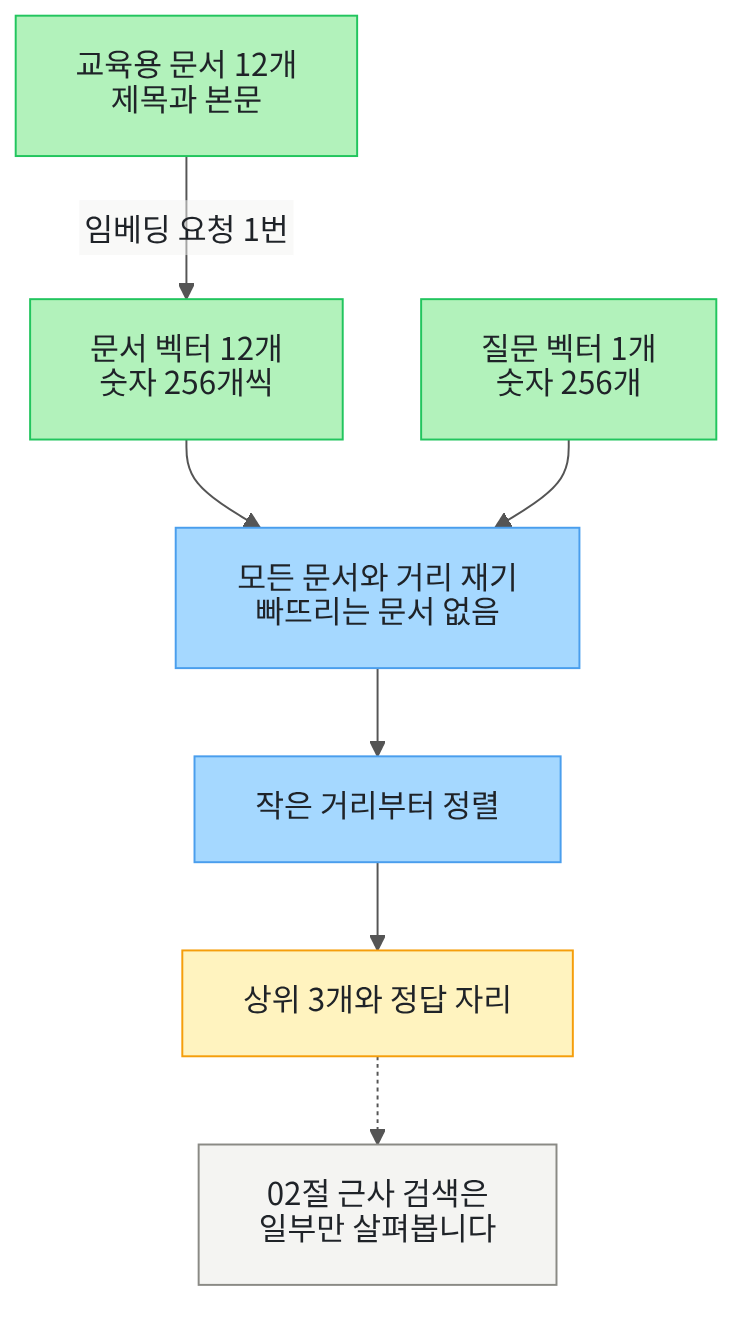

정확 검색은 질문 벡터 하나를 문서 벡터 열두 개 모두와 잽니다.
빠뜨리는 문서가 없으므로 뒤 절의 근사 검색이 무엇을 놓쳤는지 견줄 기준선이 됩니다.
맨 아래 회색 상자는 이 노트북에서 실행하지 않는 단계입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `python-dotenv: 1.2.3`이 보입니다.
셋째 줄 `numpy: 2.5.3`도 보입니다. 세 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
패키지 NumPy는 Ch 5 02절에서 코사인 유사도를 계산할 때 쓴 패키지입니다. 같은 짧은 이름 `np`로 불러옵니다.
자료 파일을 딕셔너리로 바꿀 때는 `json`을 씁니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 5 02절 `cosine_similarity()`와 Ch 11 지표 함수 네 개를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`, 02절 `recall_at()`·`mean_score()`입니다.

In [2]:
# 자료 파일 읽기·벡터 계산·임베딩에 쓸 이름을 불러옵니다
import json

import numpy as np
from langchain_openai import OpenAIEmbeddings
# Ch 5 02절과 Ch 11 01·02절 함수 다섯 개를 도구 파일에서 가져옵니다
from rag_tools import cosine_similarity, find_gold_rank, mean_score
from rag_tools import recall_at, unique_doc_ids

print("불러온 이름:", "json", "numpy", "OpenAIEmbeddings")

불러온 이름: json numpy OpenAIEmbeddings


**결과 읽기** — 출력 줄은 `불러온 이름: json numpy OpenAIEmbeddings` 하나입니다.
이름 `json`은 Python에 들어 있어 설치가 필요 없습니다.
도구 파일에서 가져온 함수 다섯 개는 출력하지 않습니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다.
Ch 10 01절·Ch 11 01절과 같은 코드입니다. 후보 경로를 차례로 보고 자료 폴더가 있는 곳에서 멈춥니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보, 실습 폴더 맨 위에서 열면 둘째 후보가 나옵니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [5]:
# 이 절에서 읽을 문서 파일과 질문 파일을 불러옵니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/core-documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/core-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — `문서 수: 12`와 `질문 수: 8`이 보입니다.
이 문서 12개는 이 챕터 앞부분 여섯 절이 함께 쓰는 교육용 자료입니다.
Ch 9~Ch 11이 쓴 미르시립도서관 PDF와는 다른 파일입니다.

## 2. 문서와 질문 살펴보기

문서 한 개와 질문 한 개를 펼쳐 칸 이름을 확인합니다.
정답 문서 ID가 어느 칸에 들어 있는지 먼저 보아야 뒤에서 재현율을 낼 수 있습니다.

In [6]:
# 문서 한 개와 질문 한 개의 칸 이름과 값을 봅니다
first_doc = docs[0]
first_query = queries[0]
print("문서의 칸 이름:", first_doc.keys())
print("첫 문서:", first_doc["doc_id"], "|", first_doc["category"], "|", first_doc["title"])
print("질문의 칸 이름:", first_query.keys())
print("첫 질문:", first_query["qid"], "|", first_query["question"])
print("첫 질문의 정답 문서 ID:", first_query["gold_doc_id"])

문서의 칸 이름: dict_keys(['doc_id', 'category', 'title', 'text'])
첫 문서: LIB-001 | library | 도서 대출 기간
질문의 칸 이름: dict_keys(['qid', 'question', 'gold_doc_id', 'kind'])
첫 질문: C01 | 책을 빌릴 수 있는 기간은 며칠인가요?
첫 질문의 정답 문서 ID: LIB-001


**결과 읽기** — 문서의 칸은 `doc_id`·`category`·`title`·`text` 네 개입니다.
첫 문서는 `LIB-001`이고 갈래는 `library`, 제목은 「도서 대출 기간」입니다.
질문의 칸은 `qid`·`question`·`gold_doc_id`·`kind` 네 개이고 첫 질문은 `C01`입니다.
정답 문서 ID 칸 이름이 `gold_doc_id` 하나짜리 글이라는 점을 기억해 둡니다.
Ch 11 평가셋은 같은 뜻을 목록 칸 `gold_doc_ids`로 담았습니다.

다음 셀은 임베딩 모델과 벡터의 숫자 개수를 정합니다.
이 챕터는 숫자 256개로 고정합니다. 02절 pgvector 표의 벡터 칸도 같은 256입니다.

In [7]:
# 이 챕터가 쓸 임베딩 모델과 벡터의 숫자 개수를 정합니다(요청은 아직 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256


**결과 읽기** — `임베딩 모델 이름: text-embedding-3-small`과 `벡터의 숫자 개수 설정: 256`이 보입니다.
이 셀은 객체만 만들므로 요청을 보내지 않습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

다음 셀은 이 절에서 되풀이해 쓸 값에 이름을 붙입니다.

In [8]:
# 이 절에서 되풀이해 쓸 값에 이름을 붙입니다
similarity_top = 1
doubling_factor = 2
cutoff_values = [1, 2, 3]
cutoff_three = 3
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("자르는 자리 세 가지:", cutoff_values)

코사인 유사도의 가장 큰 값: 1
자르는 자리 세 가지: [1, 2, 3]


**결과 읽기** — `코사인 유사도의 가장 큰 값: 1`과 `자르는 자리 세 가지: [1, 2, 3]`이 보입니다.
자르는 자리는 순위 목록을 앞에서 몇 개까지 볼지 정한 약속입니다.
Ch 11은 쪽 90개를 색인해서 자리 5와 자리 50을 썼습니다.
이 절은 문서가 12개뿐이라 자리 1·2·3으로 좁혔습니다.

## 3. 벡터로 바꾸기

문서 12개를 한 번에 임베딩합니다.
제목과 본문을 한 칸 띄어 이어 붙인 글을 보냅니다.

In [9]:
# 문서 12개의 제목과 본문을 이어 붙여 한 번에 임베딩합니다(임베딩 요청 1번)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
doc_vectors = embedding_model.embed_documents(doc_texts)
print("문서 벡터 수:", len(doc_vectors))
print("첫 문서 벡터의 숫자 개수:", len(doc_vectors[0]))
print("문서 ID 목록:")
print(doc_ids)

문서 벡터 수: 12
첫 문서 벡터의 숫자 개수: 256
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — `문서 벡터 수: 12`와 `첫 문서 벡터의 숫자 개수: 256`이 보입니다.
문서 ID 목록은 라벨 줄 아래에 한 줄로 나옵니다. `LIB-001`부터 `ACC-004`까지 열두 개입니다.
문서 열두 개를 한 번에 보냈으므로 임베딩 요청은 한 번입니다.

다음 셀은 질문 여덟 개를 하나씩 임베딩합니다.

In [10]:
# 질문 8개를 하나씩 임베딩해 질문 벡터 목록을 만듭니다(임베딩 요청 8번)
query_vectors = []
for query in queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("질문 벡터 수:", len(query_vectors))
print("첫 질문 벡터의 숫자 개수:", len(query_vectors[0]))

질문 벡터 수: 8
첫 질문 벡터의 숫자 개수: 256


**결과 읽기** — `질문 벡터 수: 8`과 `첫 질문 벡터의 숫자 개수: 256`이 보입니다.
질문은 하나씩 보내므로 요청이 여덟 번입니다. 여기까지 요청은 모두 아홉 번입니다.
문서 벡터와 질문 벡터의 숫자 개수가 같아야 같은 자로 잴 수 있습니다.

## 4. 벡터 길이 재기

벡터 길이는 같은 자리 숫자를 제곱해 모두 더한 뒤 제곱근을 씌운 값입니다.
Ch 5 02절에서 NumPy 함수 `np.linalg.norm()`으로 벡터 하나의 길이를 쟀습니다.
길이가 모두 1에 가까우면 두 가지 자의 순위가 비슷해질 수 있습니다.

다음 셀은 문서 벡터 열두 개를 표 하나로 묶어 길이를 한꺼번에 잽니다.
속성 `shape`에는 표의 행 수와 칸 수가 들어 있습니다.
인자 `axis=1`을 주면 표의 행마다 따로 길이를 잽니다.

In [11]:
# 문서 벡터 열두 개를 표 하나로 묶고 행마다 길이를 잽니다
doc_matrix = np.array(doc_vectors)
print("문서 벡터 표의 모양:", doc_matrix.shape)
# axis=1을 주면 표의 행(문서 벡터 하나)마다 따로 길이를 잽니다
doc_lengths = np.linalg.norm(doc_matrix, axis=1)
print("문서 벡터 길이(소수 둘째 자리):")
print(np.round(doc_lengths, 2).tolist())

문서 벡터 표의 모양: (12, 256)
문서 벡터 길이(소수 둘째 자리):
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


**결과 읽기** — 출력 줄 `문서 벡터 표의 모양: (12, 256)`은 행 12개와 칸 256개라는 뜻입니다.
행 하나가 문서 벡터 하나입니다.
라벨 줄 아래에 길이 열두 개가 한 줄로 나옵니다. 모두 `1.0`입니다.

소수 셋째 자리 아래는 실행마다 조금 달라지므로 `np.round()`로 둘째 자리까지만 남겼습니다.
길이를 1로 맞춘 벡터를 단위 길이 벡터라고 부릅니다.
이 임베딩 모델은 따로 맞추지 않아도 단위 길이에 가까운 값을 보냈습니다.

## 5. 두 가지 자 만들기

코사인 유사도는 점곱을 두 길이의 곱으로 나눈 값입니다.
Ch 5 02절에서 배운 이 계산을 NumPy로 적은 함수 `cosine_similarity()`를 준비 셀에서 가져왔습니다.
코사인 유사도는 클수록 가깝습니다. 가까운 것부터 정렬하려면 값이 작을수록 가까운 자가 편합니다.

그래서 가장 큰 값 1에서 유사도를 뺀 값을 코사인 거리로 씁니다.
02절 pgvector의 `<=>` 연산자가 내는 값도 같은 코사인 거리입니다.

In [12]:
# 코사인 유사도를 코사인 거리로 바꾸는 함수를 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    # 가장 큰 값 1에서 빼면 값이 작을수록 가까운 자가 됩니다
    return similarity_top - similarity

**결과 읽기** — 정의 셀이라 출력이 없습니다.

L2 거리는 두 점 사이의 직선거리입니다.
같은 자리 숫자의 차를 제곱해 모두 더한 뒤 제곱근을 씌웁니다.
NumPy 배열끼리 빼면 같은 자리 숫자끼리 뺀 배열이 나옵니다.
그 배열의 길이를 `np.linalg.norm()`으로 재면 L2 거리가 됩니다.

In [13]:
# 두 벡터의 L2 거리(같은 자리 숫자의 차를 제곱해 더한 뒤 제곱근을 씌운 값)를 정의합니다
def l2_distance(first, second):
    # 배열끼리 빼면 같은 자리 숫자끼리 뺀 차를 담은 배열이 나옵니다
    gap = np.array(first) - np.array(second)
    # 차를 담은 배열의 길이가 곧 L2 거리입니다
    return np.linalg.norm(gap)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 첫 질문과 첫 문서 사이를 두 자로 잽니다.
단위 길이 벡터에서는 L2 거리를 두 번 곱한 값이 코사인 거리의 두 배와 같아집니다.

In [14]:
# 첫 질문과 첫 문서 사이를 두 자로 재고 두 값의 관계를 봅니다
first_question_vector = query_vectors[0]
first_doc_vector = doc_vectors[0]
first_cosine = cosine_distance(first_question_vector, first_doc_vector)
first_l2 = l2_distance(first_question_vector, first_doc_vector)
squared_l2 = first_l2 * first_l2
doubled_cosine = first_cosine * doubling_factor
print("코사인 거리:", round(first_cosine, 2))
print("L2 거리:", round(first_l2, 2))
print("L2 거리를 두 번 곱한 값:", round(squared_l2, 2))
print("코사인 거리를 두 배로 한 값:", round(doubled_cosine, 2))

코사인 거리: 0.56
L2 거리: 1.06
L2 거리를 두 번 곱한 값: 1.12
코사인 거리를 두 배로 한 값: 1.12


**결과 읽기** — `코사인 거리: 0.56`과 `L2 거리: 1.06`이 보입니다.
두 값의 크기는 다르지만 `L2 거리를 두 번 곱한 값: 1.12`와 `코사인 거리를 두 배로 한 값: 1.12`가 같습니다.
단위 길이 벡터에서는 한쪽이 커질 때 다른 쪽도 커지므로 정렬 결과가 같아집니다.
길이가 1이 아닌 벡터에서는 이 관계가 성립하지 않습니다. 이번에 그 경우는 실행하지 않았습니다.

## 6. 정확 검색 만들기

정확 검색은 질문 벡터를 문서 벡터 모두와 재는 방법입니다.
다음 셀은 자 이름을 받아 거리 목록을 만듭니다.

In [15]:
# 질문 벡터 하나를 문서 벡터 열두 개 모두와 재어 거리 목록을 반환합니다
def measure_all(question_vector, distance_name):
    distance_list = []
    for doc_vector in doc_vectors:
        if distance_name == "코사인":
            distance_list.append(cosine_distance(question_vector, doc_vector))
        else:
            distance_list.append(l2_distance(question_vector, doc_vector))
    return distance_list

**결과 읽기** — 정의 셀이라 출력이 없습니다.

거리 목록을 작은 값부터 늘어놓으면 가까운 순서가 됩니다.
함수 `np.argsort(목록)`는 값을 직접 정렬하지 않고 작은 값부터 그 자리 번호를 차례로 줍니다.
다음 셀은 그 자리 번호로 문서 ID와 거리를 함께 꺼냅니다.

In [16]:
# 거리가 작은 문서부터 순위 목록을 만듭니다(거리는 작을수록 가깝습니다)
def rank_by_distance(id_list, distance_list):
    ranked = []
    # np.argsort(목록)는 값이 작은 것부터 그 자리 번호를 차례로 담은 배열을 반환합니다
    for position in np.argsort(distance_list):
        ranked.append({"doc_id": id_list[position], "거리": round(distance_list[position], 2)})
    return ranked

**결과 읽기** — 정의 셀이라 출력이 없습니다.

## 7. 실행 1 — 코사인 거리

실행 전에 예상해 봅니다. 첫 질문은 「책을 빌릴 수 있는 기간은 며칠인가요?」이고 정답 문서는 `LIB-001`입니다.
대출 기간을 적은 문서가 앞자리에 오면 좋겠습니다.

In [17]:
# 실행 1: 첫 질문을 코사인 거리로 문서 12개 모두와 재어 가까운 순서를 만듭니다
cosine_distances = measure_all(first_question_vector, "코사인")
cosine_ranked = rank_by_distance(doc_ids, cosine_distances)
print("재어 본 문서 수:", len(cosine_distances))
print("순위 | 문서 ID | 코사인 거리")
for rank_number in range(cutoff_three):
    row = cosine_ranked[rank_number]
    print(rank_number + 1, "|", row["doc_id"], "|", row["거리"])

재어 본 문서 수: 12
순위 | 문서 ID | 코사인 거리
1 | LIB-004 | 0.43
2 | LIB-001 | 0.56
3 | LIB-003 | 0.62


**결과 읽기** — `재어 본 문서 수: 12`가 보입니다. 열두 개를 하나도 빠뜨리지 않았습니다.
라벨 줄 아래 세 줄은 `1 | LIB-004 | 0.43`, `2 | LIB-001 | 0.56`, `3 | LIB-003 | 0.62`입니다.
1위는 전자책 문서 `LIB-004`이고 정답 문서 `LIB-001`은 2위입니다.
전자책 문서에도 대출 기간 7일이 적혀 있어 질문 글과 겹치는 내용이 많았습니다.

## 8. 실행 2 — 자만 L2 거리로

질문과 문서는 그대로 두고 자만 바꿉니다.
실행 전에 예상해 봅니다. 단위 길이 벡터라면 순위가 같을 것입니다.

In [18]:
# 실행 2: 같은 질문에서 자만 L2 거리로 바꿔 같은 순서 만들기를 되풀이합니다
l2_distances = measure_all(first_question_vector, "L2")
l2_ranked = rank_by_distance(doc_ids, l2_distances)
print("재어 본 문서 수:", len(l2_distances))
print("순위 | 문서 ID | L2 거리")
for rank_number in range(cutoff_three):
    row = l2_ranked[rank_number]
    print(rank_number + 1, "|", row["doc_id"], "|", row["거리"])

재어 본 문서 수: 12
순위 | 문서 ID | L2 거리
1 | LIB-004 | 0.93
2 | LIB-001 | 1.06
3 | LIB-003 | 1.11


**결과 읽기** — 라벨 줄 아래 세 줄은 `1 | LIB-004 | 0.93`, `2 | LIB-001 | 1.06`, `3 | LIB-003 | 1.11`입니다.
문서 ID와 순서가 실행 1과 같습니다. 거리 값의 크기만 다릅니다.
예상과 맞았습니다. 이번 실행에서는 단위 길이 벡터라 두 자의 순위가 같았습니다.

## 9. 문서 ID만 남기기

지표를 내려면 순위 목록에서 문서 ID만 뽑아야 합니다.
준비 셀에서 가져온 Ch 11 01절 함수 `unique_doc_ids()`가 중복을 뺀 문서 ID 목록을 만듭니다.
다음 셀은 두 자의 순위 목록에서 문서 ID를 뽑아 개수를 견줍니다.

In [19]:
# 두 자의 순위 목록에서 문서 ID만 뽑아 길이와 앞 세 개를 견줍니다
cosine_doc_ids = unique_doc_ids(cosine_ranked)
l2_doc_ids = unique_doc_ids(l2_ranked)
print("코사인 순위 항목 수:", len(cosine_ranked), "중복을 뺀 문서 수:", len(cosine_doc_ids))
print("L2 순위 항목 수:", len(l2_ranked), "중복을 뺀 문서 수:", len(l2_doc_ids))
print("코사인 앞 세 개:", cosine_doc_ids[:cutoff_three])
print("L2 앞 세 개:", l2_doc_ids[:cutoff_three])

코사인 순위 항목 수: 12 중복을 뺀 문서 수: 12
L2 순위 항목 수: 12 중복을 뺀 문서 수: 12
코사인 앞 세 개: ['LIB-004', 'LIB-001', 'LIB-003']
L2 앞 세 개: ['LIB-004', 'LIB-001', 'LIB-003']


**결과 읽기** — `코사인 순위 항목 수: 12 중복을 뺀 문서 수: 12`이고 L2도 같습니다.
이 절은 후보 한 개가 문서 한 개라 중복 제거가 목록을 바꾸지 않았습니다.
Ch 11은 후보가 쪽이어서 한 문서의 여러 쪽이 올라왔고 중복 제거가 목록을 줄였습니다.
마지막 두 줄의 목록은 모두 `['LIB-004', 'LIB-001', 'LIB-003']`입니다.

## 10. 지표 세 함수 이어 쓰기

지표 세 함수는 준비 셀에서 가져온 Ch 11 함수입니다.
함수 `find_gold_rank()`는 정답 문서가 몇 번째 자리에 있는지 찾습니다.
함수 `recall_at()`은 자르는 자리까지 자른 목록에 정답 문서가 들어온 비율을 냅니다.
함수 `mean_score()`는 질문마다 낸 점수를 같은 무게로 평균합니다.

다음 셀은 첫 질문에서 두 자의 정답 자리와 재현율을 봅니다.
Ch 11 함수는 정답 문서 ID를 목록으로 받으므로 글 하나를 목록에 담아 넘깁니다.

In [20]:
# 첫 질문의 정답 자리와 자르는 자리별 재현율을 두 자에서 봅니다
first_gold_doc_ids = [first_query["gold_doc_id"]]
print("정답 문서 ID:", first_gold_doc_ids)
print("코사인 정답 자리:", find_gold_rank(cosine_doc_ids, first_gold_doc_ids))
print("L2 정답 자리:", find_gold_rank(l2_doc_ids, first_gold_doc_ids))
print("코사인 자리 3 재현율:", recall_at(cosine_doc_ids, first_gold_doc_ids, cutoff_three))
print("L2 자리 3 재현율:", recall_at(l2_doc_ids, first_gold_doc_ids, cutoff_three))

정답 문서 ID: ['LIB-001']
코사인 정답 자리: 2
L2 정답 자리: 2
코사인 자리 3 재현율: 1.0
L2 자리 3 재현율: 1.0


**결과 읽기** — `정답 문서 ID: ['LIB-001']`이고 두 자 모두 `정답 자리: 2`입니다.
자리 3 재현율은 두 자 모두 `1.0`입니다. 자리 3까지 보면 정답 문서가 들어옵니다.
정답 자리가 2였으므로 자리 1까지만 보면 재현율이 0이 됩니다.

## 11. 질문 여덟 개로 넓히기

질문 하나로는 자를 고를 수 없습니다.
다음 셀은 질문 하나를 한 자로 재어 기록 한 줄을 만드는 함수입니다.

In [21]:
# 질문 하나를 한 자로 재어 기록 한 줄을 만듭니다
def score_one(query_index, distance_name):
    query = queries[query_index]
    gold_doc_ids = [query["gold_doc_id"]]
    distance_list = measure_all(query_vectors[query_index], distance_name)
    ranked = rank_by_distance(doc_ids, distance_list)
    found_ids = unique_doc_ids(ranked)
    row = {"자": distance_name, "질문": query["qid"]}
    row["정답 자리"] = find_gold_rank(found_ids, gold_doc_ids)
    for cutoff in cutoff_values:
        row["자리 " + str(cutoff)] = recall_at(found_ids, gold_doc_ids, cutoff)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 질문 여덟 개를 두 자로 모두 재어 기록 줄을 담습니다.
질문 벡터와 문서 벡터를 이미 만들어 두었으므로 임베딩 요청이 늘지 않습니다.

In [22]:
# 질문 여덟 개를 두 자로 모두 재어 기록 줄을 담습니다(임베딩 요청은 더 보내지 않습니다)
score_rows = []
for distance_name in ["코사인", "L2"]:
    for query_index in range(len(queries)):
        score_rows.append(score_one(query_index, distance_name))
print("담은 기록 줄 수:", len(score_rows))

담은 기록 줄 수: 16


**결과 읽기** — `담은 기록 줄 수: 16`이 보입니다. 질문 여덟 개에 자 두 가지를 곱한 수입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [23]:
# 자·질문·정답 자리·자리 1·자리 3 다섯 칸을 라벨 줄 아래에 차례로 출력합니다
print("자 | 질문 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율")
for row in score_rows:
    print(row["자"], "|", row["질문"], "|", row["정답 자리"], "|", row["자리 1"], "|", row["자리 3"])

자 | 질문 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율
코사인 | C01 | 2 | 0.0 | 1.0
코사인 | C02 | 7 | 0.0 | 0.0
코사인 | C03 | 1 | 1.0 | 1.0
코사인 | C04 | 1 | 1.0 | 1.0
코사인 | C05 | 1 | 1.0 | 1.0
코사인 | C06 | 1 | 1.0 | 1.0
코사인 | C07 | 1 | 1.0 | 1.0
코사인 | C08 | 1 | 1.0 | 1.0
L2 | C01 | 2 | 0.0 | 1.0
L2 | C02 | 7 | 0.0 | 0.0
L2 | C03 | 1 | 1.0 | 1.0
L2 | C04 | 1 | 1.0 | 1.0
L2 | C05 | 1 | 1.0 | 1.0
L2 | C06 | 1 | 1.0 | 1.0
L2 | C07 | 1 | 1.0 | 1.0
L2 | C08 | 1 | 1.0 | 1.0


**결과 읽기** — 라벨 줄 아래 열여섯 줄에서 정답 자리가 대부분 `1`입니다.
질문 `C01`은 두 자 모두 정답 자리 `2`입니다.
질문 `C02`는 두 자 모두 정답 자리 `7`이라 자리 3 재현율이 `0.0`입니다.

질문 C02는 「책을 늦게 반납하면 돈을 내나요?」입니다.
정답 문서인 연체 안내 문서에는 연체료를 부과하지 않는다고 적혀 있습니다.
질문 글과 겹치는 낱말이 적어 자리가 뒤로 밀렸습니다.
같은 질문 줄에서 코사인과 L2의 네 칸이 모두 같습니다.

## 12. 두 자와 자르는 자리 견주기

질문 평균은 질문마다 낸 점수를 같은 무게로 더해 나눈 값입니다.
자르는 자리를 넓히면 재현율이 어디까지 올라가는지 봅니다.

In [24]:
# 두 자의 질문 평균 재현율을 자르는 자리마다 견줍니다
print("자 | 자르는 자리 | 질문 평균 재현율")
for distance_name in ["코사인", "L2"]:
    picked = []
    for row in score_rows:
        if row["자"] == distance_name:
            picked.append(row)
    for cutoff in cutoff_values:
        scores = []
        for row in picked:
            scores.append(row["자리 " + str(cutoff)])
        print(distance_name, "|", cutoff, "|", mean_score(scores))

자 | 자르는 자리 | 질문 평균 재현율
코사인 | 1 | 0.75
코사인 | 2 | 0.875
코사인 | 3 | 0.875
L2 | 1 | 0.75
L2 | 2 | 0.875
L2 | 3 | 0.875


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
코사인은 자리 1에서 `0.75`, 자리 2에서 `0.875`, 자리 3에서 `0.875`입니다.
L2도 세 값이 같습니다.

자리 2에서 값이 올라간 것은 질문 C01의 정답 문서가 자리 2였기 때문입니다.
자리 3에서 값이 그대로인 것은 남은 질문 C02의 정답 자리가 7이기 때문입니다.
문서가 12개뿐이라 자리 12까지 넓히면 재현율이 1.0이 됩니다.
이 값은 자를 고르는 데 쓸 수 없습니다.

## 정리

1. 정확 검색은 질문 벡터를 문서 벡터 모두와 재므로 후보에서 빠지는 문서가 없습니다.
2. 코사인 유사도는 클수록 가깝고 L2 거리는 작을수록 가까워 정렬 방향이 반대입니다. 유사도를 1에서 빼면 같은 방향의 자가 됩니다.
3. 이번 실행에서는 문서 벡터가 단위 길이라 두 자의 순위와 재현율이 모두 같았습니다.

02절에서는 같은 문서 12개 벡터를 pgvector 표에 넣고 HNSW 색인으로 검색합니다.
이 절의 정확 검색 순위가 그 결과를 견줄 기준선입니다.